# Actividad — Valores atípicos y EDA con California Housing
**Aprendizaje Supervisado · Unidad 1 · Preparación de datos y análisis exploratorio (EDA)**

**Qué haremos.** En la presentación vimos las herramientas del EDA. Hoy las usarás sobre un conjunto real y, sobre todo,
**tomarás decisiones**: ¿qué hago con cada valor raro? ¿en qué variables puedo confiar para una correlación?

| Parte | Pregunta que responde | Tema de la presentación |
|---|---|---|
| 1 | ¿Qué hay en el conjunto de datos? | Tipos de variable, el dataset |
| 2 | ¿Qué dicen $\bar x$, mediana, $s$, asimetría y curtosis? | Estadística descriptiva |
| 3 | ¿Qué forma tiene cada variable? | Histogramas |
| 4 | ¿Cuántos atípicos marcan los boxplots y la regla del IQR? | Boxplot y $1.5\cdot\mathrm{IQR}$ |
| 5 | ¿Qué son esas filas extremas? ¿error, dato raro o tope? | Un atípico, ¿qué hago con él? |
| 6 | ¿Qué efecto tienen los topes (5.0 y 52)? | Censura |
| 7 | ¿Qué cambia si recorto o aplico logaritmo? | Transformaciones |
| 8 | ¿Cómo se relacionan las variables con el precio? | Análisis bivariado |
| 9 | ¿Qué dice la matriz de correlación? ¿hay multicolinealidad? | Matriz y heatmap |
| 10 | Resumen y entregable | Receta de EDA |

**Tiempo estimado:** 40–50 minutos de trabajo individual.

**Entregable:** este notebook ejecutado, con sus respuestas en las celdas ✏️, y la **tabla de decisiones**
de la Parte 10: *variable · % de atípicos · decisión · justificación*.

**Cómo trabajar.** Ejecuta las celdas en orden. Donde dice ✏️ hay una pregunta o un parámetro que debes cambiar tú
(escribe tus respuestas en la celda de texto que sigue a la pregunta, bajo «**Respuesta:**»).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
})
AZUL, NARANJA, VERDE, ROJO = "#065A82", "#E07A1F", "#02C39A", "#C0392B"
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", message=".*vert.*")  # aviso de versiones nuevas de matplotlib sobre boxplot(vert=...)

---
## Parte 1 — Cargar y conocer los datos

El conjunto **California Housing** (Pace y Barry, 1997) viene del censo de 1990. **Cada fila es un distrito censal**
(no una vivienda): sus valores son medianas o promedios de muchos hogares.

| Variable | Qué describe |
|---|---|
| `MedInc` | ingreso mediano del distrito (en decenas de miles de USD) |
| `HouseAge` | edad mediana de las viviendas (años) |
| `AveRooms` | habitaciones promedio por hogar |
| `AveBedrms` | dormitorios promedio por hogar |
| `Population` | número de habitantes del distrito |
| `AveOccup` | ocupantes promedio por hogar |
| `Latitude`, `Longitude` | ubicación del distrito |
| `MedHouseVal` | **objetivo**: valor mediano de la vivienda (en cientos de miles de USD) |

> La primera vez, `fetch_california_housing` descarga el archivo (≈1 MB) y lo guarda en `~/scikit_learn_data`; se necesita conexión a internet.

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()  # trabajamos sobre una copia: el original queda intacto
print("Forma (filas, columnas):", df.shape)
df.head()

Forma (filas, columnas): (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.0,6.984,1.024,322.0,2.556,37.88,-122.23,4.526
1,8.301,21.0,6.238,0.972,2401.0,2.110,37.86,-122.22,3.585
2,7.257,52.0,8.288,1.073,496.0,2.802,37.85,-122.24,3.521
3,5.643,52.0,5.817,1.073,558.0,2.548,37.85,-122.25,3.413
4,3.846,52.0,6.282,1.081,565.0,2.181,37.85,-122.25,3.422


In [3]:
df.info()
print("\nFaltantes por columna:")
print(df.isna().sum().to_string())
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Faltantes por columna:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0

Filas duplicadas: 0


✏️ **Pregunta 1.1.** ¿Cuántas filas y columnas hay? ¿Hay faltantes o duplicados? ¿Qué tipo de variable es cada columna (continua, discreta…)?

✏️ **Pregunta 1.2.** Cada fila es un *distrito*, no una casa. ¿Qué consecuencia tiene esto cuando una variable dice «promedio» o «mediana»?
(Pista: ¿cómo podría ser un promedio de 140 habitaciones por hogar?)

**Respuesta:**

<strong>1.1.</strong> Hay 20640 filas y 9 columnas, sin faltantes y sin duplicados.

Tipos de variables

| Tipo de variable | Columnas                                                                |
|------------------|-------------------------------------------------------------------------|
| Continua         | MedInc, AvgRooms, AveBedrms, AveOccup, Latitude, Longitude, MedHouseVal |
| Discreta         | HouseAge, Population                                                    |

<strong>1.2.</strong>Como cada fila es un distrito, los valores describen al grupo y no a una casa individual. Las variables de promedio se calculan dividiendo entre el número de hogares del distrito, así que en distritos con muy pocos hogares pueden aparecer valores extremos, como 140 habitaciones por hogar. Esos valores no son necesariamente errores, por lo que conviene revisarlos, entender qué significan y decidir qué hacer con ellos.

---
## Parte 2 — Estadística descriptiva: media, varianza, asimetría y curtosis

Recordatorio (con $z_i = (x_i-\bar x)/s$):

$$\gamma_1=\frac1n\sum_{i=1}^n z_i^3 \quad(\text{asimetría}),\qquad \kappa-3=\frac1n\sum_{i=1}^n z_i^4-3 \quad(\text{curtosis en exceso}).$$

`pandas` calcula ambas con una pequeña corrección para muestras finitas; con $n=20\,640$ la diferencia es mínima.

In [4]:
def resumen(d):
    t = d.agg(["mean", "median", "std", "min", "max"]).T
    t["asimetria"] = d.skew()
    t["curtosis_exc"] = d.kurt()
    t["media - mediana"] = t["mean"] - t["median"]
    return t


resumen(df).round(2)

,mean,median,std,min,max,asimetria,curtosis_exc,media - mediana
MedInc,3.87,3.53,1.90,0.50,15.00,1.65,4.95,0.34
HouseAge,28.64,29.00,12.59,1.00,52.00,0.06,-0.80,-0.36
AveRooms,5.43,5.23,2.47,0.85,141.91,20.70,879.35,0.20
AveBedrms,1.10,1.05,0.47,0.33,34.07,31.32,1636.71,0.05
Population,1425.48,1166.00,1132.46,3.00,35682.00,4.94,73.55,259.48
AveOccup,3.07,2.82,10.39,0.69,1243.33,97.64,10651.01,0.25
Latitude,35.63,34.26,2.14,32.54,41.95,0.47,-1.12,1.37
Longitude,-119.57,-118.49,2.00,-124.35,-114.31,-0.30,-1.33,-1.08
MedHouseVal,2.07,1.80,1.15,0.15,5.00,0.98,0.33,0.27


In [5]:
# Comprobación «a mano» con MedInc: lo que hace pandas, paso por paso
x = df["MedInc"]
z = (x - x.mean()) / x.std(ddof=0)  # puntaje z
g1 = (z ** 3).mean()  # asimetría
exceso = (z ** 4).mean() - 3  # curtosis en exceso
print(f"a mano : asimetría = {g1:.4f}   curtosis en exceso = {exceso:.4f}")
print(f"pandas : asimetría = {x.skew():.4f}   curtosis en exceso = {x.kurt():.4f}")

a mano : asimetría = 1.6465   curtosis en exceso = 4.9510
pandas : asimetría = 1.6467   curtosis en exceso = 4.9525


In [6]:
# ¿Qué variables tienen la forma «más rara»? ordenamos por |asimetría|
resumen(df)[["asimetria", "curtosis_exc"]].abs().sort_values("asimetria", ascending=False).round(1)

,asimetria,curtosis_exc
AveOccup,97.6,10651.0
AveBedrms,31.3,1636.7
AveRooms,20.7,879.4
Population,4.9,73.6
MedInc,1.6,5.0
MedHouseVal,1.0,0.3
Latitude,0.5,1.1
Longitude,0.3,1.3
HouseAge,0.1,0.8


✏️ **Pregunta 2.1.** En `MedInc`, ¿qué signo tiene `media - mediana`? ¿Concuerda con el signo de la asimetría? Explícalo con una frase.

✏️ **Pregunta 2.2.** Menciona las **tres variables** con mayor asimetría. ¿Qué dice la curtosis de la que tiene el valor más grande?
(Recuerda: la curtosis alta habla de *colas pesadas*, es decir, de valores extremos.)

✏️ **Pregunta 2.3.** `AveOccup` tiene media ≈ 3 pero un máximo de más de 1 000. ¿Cuántas desviaciones estándar por encima de la media está ese máximo? Calcúlalo en la celda de abajo.

**Respuesta:**

<strong>2.1.</strong> media - mediana es positiva y la asimetría también, así que sí concuerdan. Esto ocurre porque unos pocos distritos con ingresos muy altos jalan la media hacia arriba mientras que la mediana casi no se mueve: la distribución tiene una cola larga a la derecha (asimetría positiva).

<strong>2.2.</strong> Las tres variables con mayor asimetría son: `AveOccup`, `AveBedrms` y `AveRooms`. La curtosis en exceso de AveOccup es ≈ 10,651, cuando en una distribución normal sería 0. Esto indica colas extremadamente pesadas: la mayoría de los distritos tienen valores cercanos a la media, pero unos pocos están enormemente alejados de ella.

In [7]:
# ✏️ Pregunta 2.3: puntaje z del valor máximo de AveOccup
v = df["AveOccup"]
z_max = (v.max() - v.mean()) / v.std()
print(f"El máximo de AveOccup está a {z_max:.0f} desviaciones estándar de la media")

El máximo de AveOccup está a 119 desviaciones estándar de la media


---
## Parte 3 — Forma de cada variable: histogramas

Dibujamos la media (naranja, discontinua) y la mediana (verde). Para poder **ver** la forma, recortamos el 0.5 % superior
*solo en el dibujo* (los datos no se modifican).

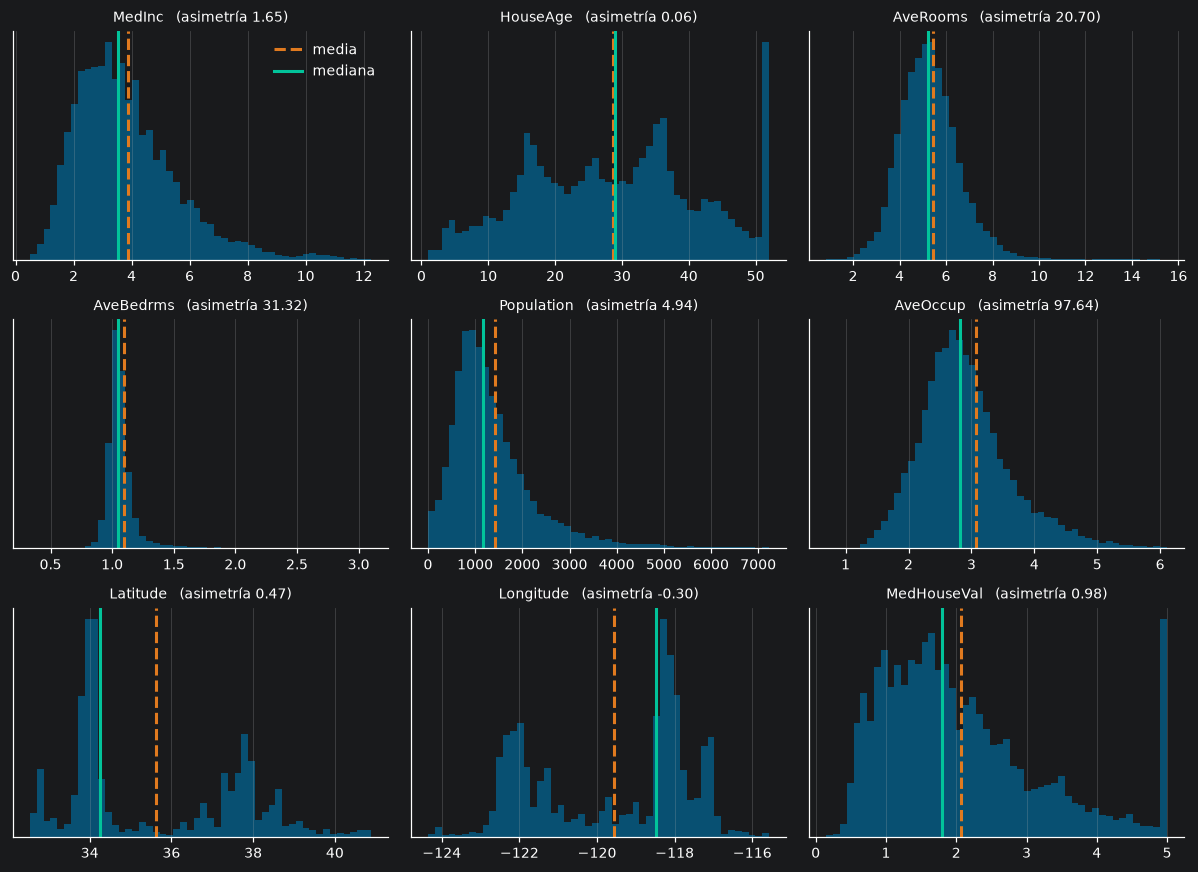

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for ax, c in zip(axes.ravel(), df.columns):
    x = df[c]
    tope = x.quantile(0.995)  # ✏️ prueba con 1.0 para AveOccup y compara
    # if c == "AveOccup":
    #     tope = x.quantile(1.0)
    ax.hist(x[x <= tope], bins=50, color=AZUL, alpha=0.85)
    ax.axvline(x.mean(), color=NARANJA, lw=2, ls="--", label="media")
    ax.axvline(x.median(), color=VERDE, lw=2, label="mediana")
    ax.set_title(f"{c}   (asimetría {x.skew():.2f})", fontsize=9)
    ax.set_yticks([])
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

✏️ **Pregunta 3.1.** Describe con una frase la forma de `MedInc`, `HouseAge`, `Population` y `MedHouseVal`.
¿Cuáles tienen una barra «de más» al extremo derecho? (La estudiaremos en la Parte 6.)

✏️ **Pregunta 3.2.** Cambia `tope = x.quantile(0.995)` por `x.quantile(1.0)` y mira `AveOccup`. ¿Qué pasa con el histograma y por qué?

**Respuesta:**

<strong>3.1.</strong> `MedInc` es asimétrica positiva, `HouseAge` es bastante simétrica, `Population` es asimétrica positiva y `MedHouseVal` es asimétrica positiva. Tanto `HouseAge` como `MedHouseVal` tienen una barra al extremo derecho.

<strong>3.2.</strong>  Al usar quantile(1.0) se incluyen todos los datos, y el histograma de AveOccup se convierte en una sola barra pegada a la izquierda, sin forma visible. Esto ocurre porque el máximo es ≈ 1,243 mientras que la media y la mediana rondan 3. Las 50 barras se reparten entre 0 y 1,243 (unas 25 unidades cada una),así que casi todos los distritos caen en la primera barra. Unos pocos valores extremos bastan para que no se vea la forma de la mayoría.


---
## Parte 4 — Identificar atípicos con boxplots y la regla del IQR

**Regla de Tukey.** Con $Q_1$, $Q_3$ y $\mathrm{IQR}=Q_3-Q_1$, un dato es atípico si cae fuera de

$$[\,Q_1-k\cdot\mathrm{IQR},\ \ Q_3+k\cdot\mathrm{IQR}\,],\qquad k=1.5\ (\text{atípico})\quad\text{o}\quad k=3\ (\text{atípico extremo}).$$

Primero comprobamos con datos simulados qué fracción marca la regla cuando **sí** conocemos la distribución.

In [14]:
def cercas_iqr(s, k=1.5):
    '''Devuelve (cerca inferior, cerca superior) de la regla de Tukey.'''
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


rng = np.random.default_rng(0)
for nombre, x in [("normal", rng.normal(size=100_000)), ("lognormal", rng.lognormal(size=100_000))]:
    lo, hi = cercas_iqr(pd.Series(x))
    print(f"{nombre:10s}: {100 * ((x < lo) | (x > hi)).mean():.2f} % de los datos fuera de las cercas")

normal    : 0.72 % de los datos fuera de las cercas
lognormal : 7.82 % de los datos fuera de las cercas


✏️ **Pregunta 4.1.** En la normal, ¿qué porcentaje marca la regla? ¿Y en la lognormal (muy asimétrica)? ¿Qué te dice esto sobre interpretar
«porcentaje de atípicos» en variables con cola larga?

**Respuesta:**

<strong>4.1.</strong> En la normal marcó el 0.72% de los datos como atípicos, y en la lognormal el 7.82%, aunque en ambos casos ningún dato es un error porque son simulados. La diferencia se debe a la forma: en una variable con cola larga, la regla marca muchos valores solo por estar en la cola. Por eso un porcentaje alto de atípicos no significa que haya muchos datos malos; no hay que descartarlos solo por que la regla los marca, sino revisar sí son errores o parte real de los datos.

In [22]:
def tabla_atipicos(d, k=1.5):
    filas = []
    for c in d.columns:
        lo, hi = cercas_iqr(d[c], k)
        bajo, alto = int((d[c] < lo).sum()), int((d[c] > hi).sum())
        filas.append(dict(variable=c, cerca_inf=lo, cerca_sup=hi, n_bajo=bajo, n_alto=alto,
                          pct_atipicos=100 * (bajo + alto) / len(d), minimo=d[c].min(), maximo=d[c].max(), maximo_minus_cerca_sup=d[c].max() / hi))
    return pd.DataFrame(filas).set_index("variable")


K = 1.5  # ✏️ cambia a 3.0 y vuelve a ejecutar esta celda y la siguiente
tabla = tabla_atipicos(df, K)
tabla.round(2)

,cerca_inf,cerca_sup,n_bajo,n_alto,pct_atipicos,minimo,maximo,maximo_minus_cerca_sup
variable,,,,,,,,
MedInc,-3.98,11.28,0,140,0.68,0.50,15.00,1.33
HouseAge,-39.00,94.00,0,0,0.00,1.00,52.00,0.55
AveRooms,-0.39,10.89,0,180,0.87,0.85,141.91,13.03
AveBedrms,0.73,1.38,32,692,3.51,0.33,34.07,24.69
Population,-2027.00,4539.00,0,421,2.04,3.00,35682.00,7.86
AveOccup,-0.13,5.84,0,132,0.64,0.69,1243.33,212.91
Latitude,22.59,49.05,0,0,0.00,32.54,41.95,0.86
Longitude,-133.17,-106.64,0,0,0.00,-124.35,-114.31,1.07
MedHouseVal,-3.16,7.00,0,0,0.00,0.15,5.00,0.71


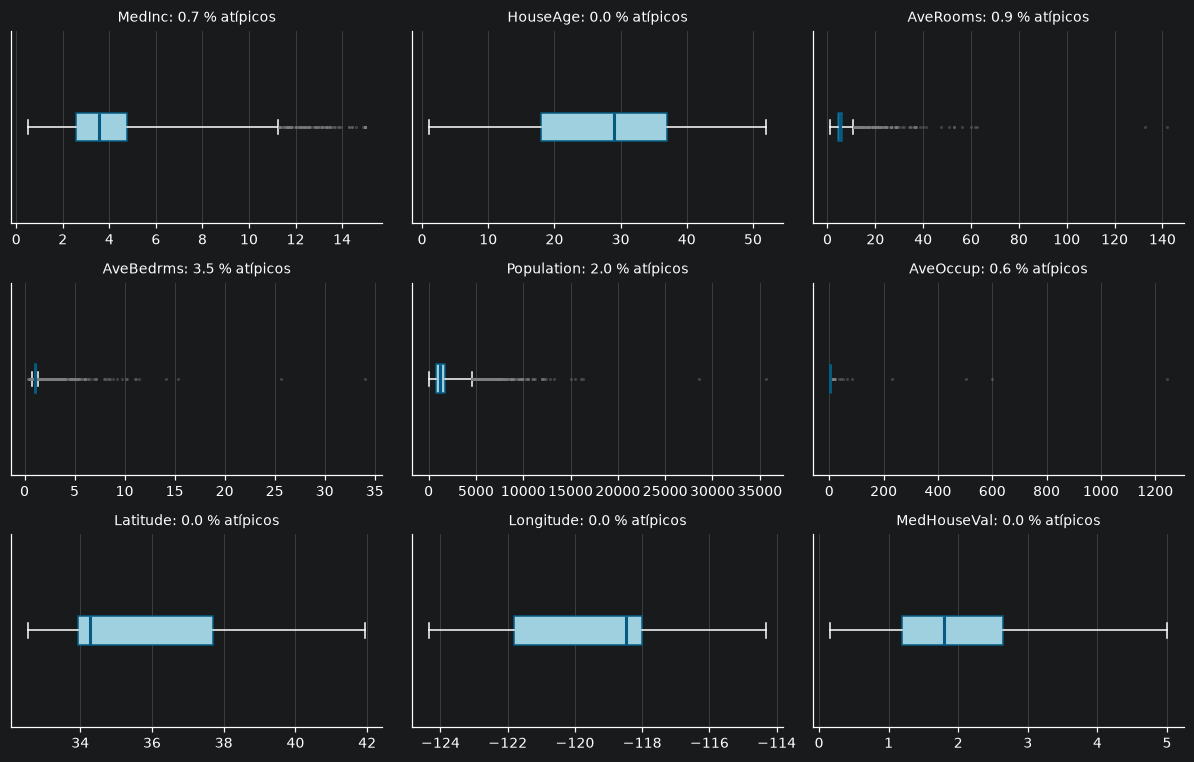

In [23]:
fig, axes = plt.subplots(3, 3, figsize=(11, 7))
for ax, c in zip(axes.ravel(), df.columns):
    ax.boxplot(df[c], vert=False, whis=K, patch_artist=True,
               boxprops=dict(facecolor="#9FD0E0", edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
               flierprops=dict(marker="o", markersize=2, markerfacecolor="gray", markeredgecolor="none", alpha=0.4))
    ax.set_yticks([])
    ax.set_title(f"{c}: {tabla.loc[c, 'pct_atipicos']:.1f} % atípicos", fontsize=9)
plt.tight_layout()
plt.show()

✏️ **Pregunta 4.2.** Con $k=1.5$: ¿qué variable tiene el mayor *porcentaje* de atípicos? ¿Cuál tiene el valor más **lejano** (compara `maximo` con `cerca_sup`)?
¿Coinciden? ¿Por qué un porcentaje alto no implica necesariamente valores absurdos?

✏️ **Pregunta 4.3.** Repite con $k=3$. ¿Qué variables casi «se limpian» y cuáles conservan atípicos extremos? ¿Cuáles tienen **0 %** y por qué
(piensa en `Latitude`, `Longitude` y `HouseAge`)?

**Respuesta:**

<strong>4.2.</strong> `AveBedrms` con 6.9% de atípicos es la variable con el porcentaje más alto. El valor más lejano lo tiene `AveOccup` (Su máximo es unas 273 veces la cerca superior) por lo que no coinciden. El porcentaje cuenta cuántos datos queda fuera; no mide qué tan lejos quedan: las cercas de AveBedrms son muy angostas (0.87 - 1.24), así que valores razonables como 1.3 recámaras por hogar ya se marcan como atípicos.

<strong>4.3.</strong> Con k = 3 las variables que casi se limpian fueron `MedInc`, `AveRooms` y `AveOccup` (menos del 1%). `AveBedrms` y `Pouplation` siguen teniendo un porcentaje notable. Además, `AveOccup` tiene poco porcentaje (0.64%), pero su máximo sigue a 213 veces la cerca, así que conserva atípicos extremos. `HouseAge`, `Latitude` `Longitude`y `MedHouseVal` tienen 0%. Latitude y Longitude son coordenadas de California por lo que no pueden salirse del mapa del estado. HouseAge y MedHouseVal tienen un tope artificial (52 y 5.0). Todo lo que era mayor se registró con el valor del tope, así que la cola está cortada. Por eso su 0% no significa que estén limpias, sino que la regla no puede ver el problema.

---
## Parte 5 — Inspeccionar las filas extremas: ¿error, dato raro o tope?

La regla del IQR dice **qué es inusual**, no **qué es incorrecto**. Para decidir hay que mirar las filas y razonar con el contexto.
Una pista útil: el número de hogares de un distrito es aproximadamente `Population / AveOccup`.

In [24]:
ext = df.nlargest(5, "AveOccup").copy()
ext["hogares (aprox.)"] = ext["Population"] / ext["AveOccup"]
print("Las 5 filas con más ocupantes por hogar:")
ext[["Population", "AveOccup", "hogares (aprox.)", "AveRooms", "MedHouseVal"]].round(1)

Las 5 filas con más ocupantes por hogar:


,Population,AveOccup,hogares (aprox.),AveRooms,MedHouseVal
19006,7460.0,1243.3,6.0,3.2,1.4
3364,4198.0,599.7,7.0,5.1,0.7
16669,6532.0,502.5,13.0,9.1,3.5
13034,6675.0,230.2,29.0,8.3,2.2
9172,8733.0,83.2,105.0,5.1,1.5


In [25]:
ext2 = df.nlargest(5, "AveRooms").copy()
ext2["hogares (aprox.)"] = ext2["Population"] / ext2["AveOccup"]
print("Las 5 filas con más habitaciones por hogar:")
ext2[["Population", "AveOccup", "hogares (aprox.)", "AveRooms", "AveBedrms", "MedHouseVal"]].round(1)

Las 5 filas con más habitaciones por hogar:


,Population,AveOccup,hogares (aprox.),AveRooms,AveBedrms,MedHouseVal
1914,30.0,2.7,11.0,141.9,25.6,5.0
1979,36.0,2.4,15.0,132.5,34.1,1.6
12447,83.0,1.8,45.0,62.4,14.1,0.9
1913,112.0,2.3,48.0,61.8,11.0,4.4
11862,28.0,1.8,16.0,59.9,15.3,0.7


✏️ **Pregunta 5.1.** Para cada uno de estos casos, clasifícalo y justifica: **(a)** error de captura / imposible, **(b)** dato real pero raro,
**(c)** tope o censura. Fíjate en los hogares aproximados: un distrito con 7 460 personas y ≈6 hogares, ¿qué tipo de lugar podría ser?
(pista: residencias universitarias, cárceles, cuarteles…) ¿Qué distritos con muchas habitaciones por hogar y muy poca población podrían ser?

✏️ **Pregunta 5.2.** ¿Tienen sentido estos distritos para un modelo que predice el **valor de la vivienda** en zonas residenciales normales?
Propón una regla (por ejemplo, un mínimo de hogares) para marcarlos o excluirlos, **y anota cuántas filas afectaría**.

**Respuesta:**

In [43]:
# ✏️ Pregunta 5.2: prueba tu regla aquí (ejemplo: marcar distritos con menos de 10 hogares)
hogares = df["Population"] / df["AveOccup"]
marca = (hogares < 10) | (df["AveRooms"] > 20) | (df["AveOccup"] > 15)
print(f"Filas marcadas: {marca.sum()} de {len(df)}  ({100 * marca.mean():.2f} %)")
df.loc[marca, ["Population", "AveOccup", "AveRooms", "MedHouseVal"]].describe().round(1)

Filas marcadas: 134 de 20640  (0.65 %)


,Population,AveOccup,AveRooms,MedHouseVal
count,134.0,134.0,134.0,134.0
mean,607.9,25.2,20.0,1.9
std,1458.0,127.1,20.7,1.2
min,3.0,0.7,1.0,0.1
25%,26.0,2.3,5.1,1.1
50%,97.5,2.6,20.1,1.6
75%,380.0,4.2,26.8,2.2
max,8733.0,1243.3,141.9,5.0


<strong>5.1.</strong> Caso 1 (7,460 personas en ≈6 hogares, AveOccup ≈ 1,243): (b) dato real pero raro. Si se leyera como una casa sería imposible, pero probablemente es un alojamiento colectivo (cárcel, residencia universitaria o cuartel), cuyos residentes cuentan como población pero no como hogares. No es un error de captura, sino un efecto de cómo se calcula el promedio.

Caso 2 (30 personas en ≈11 hogares, AveRooms ≈ 142): (b) dato real pero raro, probablemente una zona de casas vacacionales con muchas viviendas pero pocos residentes permanentes. Además, es (c) tope, porque su `MedHouseVal` es exactamente 5.0, el límite artificial del dataset, así que su valor real podría ser mayor.

<strong>5.2.</strong> No tienen sentido para un modelo que predice el valor de la vivienda en zonas residenciales normales. Son alojamientos colectivos o zonas vacacionales con valores tan extremos que pueden distorsionar lo que aprende el modelo. Propongo marcar los distritos que cumplan al menos una de estas condiciones: menos de 10 hogares, más de 20 habitaciones por hogar o más de 15 ocupantes por hogar.
```
marca = (hogares < 10) | (df["AveRooms"] > 20) | (df["AveOccup"] > 15)
```
La regla afecta a 134 filas de 20,640 (0.65%) e incluye los 10 distritos extremos de las tablas anteriores. Al ser menos del 1%, excluirlas casi no reduce el conjunto de datos.

---
## Parte 6 — Topes (censura): los picos en 5.0 y 52

En los histogramas había una barra extra al final de `MedHouseVal` y de `HouseAge`: valores **truncados** por la forma en que se publicó
el censo (valores mayores se registran como el tope). No son «atípicos»: son datos **censurados**.

MedHouseVal :   992 filas ≥ 5.0  (4.81 %)
HouseAge    :  1273 filas ≥ 52  (6.17 %)
MedInc      :    51 filas ≥ 15.0  (0.25 %)


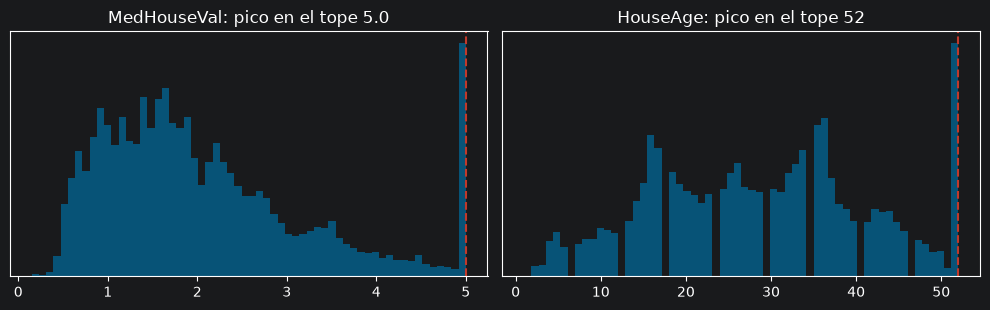

In [44]:
topes = {"MedHouseVal": 5.0, "HouseAge": 52, "MedInc": 15.0}
for c, tope in topes.items():
    n = int((df[c] >= tope).sum())
    print(f"{c:12s}: {n:5d} filas ≥ {tope}  ({100 * n / len(df):.2f} %)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, c in zip(axes, ["MedHouseVal", "HouseAge"]):
    ax.hist(df[c], bins=60, color=AZUL, alpha=0.9)
    ax.axvline(topes[c], color=ROJO, ls="--", lw=1.5)
    ax.set_title(f"{c}: pico en el tope {topes[c]}")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

In [45]:
# ¿Cómo cambia una correlación si «quitamos» las filas con tope?
sin_tope = df[df["MedHouseVal"] < 5.0]
print("r(MedInc, MedHouseVal) con topes :", round(df["MedInc"].corr(df["MedHouseVal"]), 3))
print("r(MedInc, MedHouseVal) sin topes :", round(sin_tope["MedInc"].corr(sin_tope["MedHouseVal"]), 3))
print("Filas que se perderían:", len(df) - len(sin_tope))

r(MedInc, MedHouseVal) con topes : 0.688
r(MedInc, MedHouseVal) sin topes : 0.647
Filas que se perderían: 992


✏️ **Pregunta 6.1.** ¿Por qué no es lo mismo un tope que un atípico? ¿Cuántos distritos tienen `MedHouseVal` en el tope? ¿Y `HouseAge`?

✏️ **Pregunta 6.2.** La correlación baja al quitar los topes. ¿Significa que «con topes» está mal? Pista: los distritos más caros e ingresos más altos son
justo los que fueron truncados. ¿Qué **sesgo** introduce *borrar* esas filas? Propón una alternativa (por ejemplo, agregar un indicador `es_tope`
o reportar el desempeño del modelo también en la zona no truncada).

**Respuesta:**

<strong>6.1.</strong> Un atípico es un valor real que conocemos, aunque sea inusual. Un tope es un valor censurado: el valor real se desconoce y solo sabemos que es mayor o igual al límite. Por eso la regla del IQR no detecta los topes y transformarlo no recupera la información perdida. `MedHouseVal` tiene 992 distritos en el tope de 5.0 (4.81%) y `HouseAge` tiene 1273 en el tope de 52 (6.17%).

<strong>6.2.</strong> Que la correlación baje al quitar los topes no significa que "con topes" esté mal: en los distritos más caros el precio está aplastado en 5.0, así que la relación en esa zona queda distorsionada. Sin topes, quitamos justo los distritos más caros y de ingresos más altos. Al recortar el rango de las variables, la correlación baja aunque la relación real siga existiendo. Borrar esas filas introduce un sesgo de selección: no son distritos al azar, sino los más ricos, así que el modelo no vería zonas caras y no podría predecirlas. Una alternativa es agregar una columna indicadora es_tope, que permite conservar esos distritos y que el modelo sepa que su valor no es exacto.

---
## Parte 7 — Transformar o recortar: ¿qué cambia?

Tres tratamientos habituales para colas largas:

| Tratamiento | Qué hace | Cuándo es razonable |
|---|---|---|
| **Winsorizar** (`clip`) | trunca en las cercas del IQR | los extremos son raros/dudosos pero no queremos perder filas |
| **Logaritmo** | comprime la cola derecha | variable positiva con cola larga y efectos multiplicativos |
| **Nada** | deja el dato igual | el valor extremo es real y relevante |

In [57]:
def logaritmo(s):
    # conteos (pueden valer 0): log(1 + x); promedios estrictamente positivos: log(x)
    return np.log1p(s) if s.name == "Population" else np.log(s)


def efecto(c, k=3.0):
    x = df[c]
    lo, hi = cercas_iqr(x, k)
    variantes = {
        "original": x,
        f"clip (k={k})": x.clip(lo, hi),
        "log": logaritmo(x),
    }
    filas = []
    for nombre, v in variantes.items():
        filas.append(
            dict(version=nombre, asimetria=v.skew(), curtosis_exc=v.kurt(), r_con_objetivo=v.corr(df["MedHouseVal"]),
                 spearman=v.corr(df["MedHouseVal"], method="spearman")))
    return pd.DataFrame(filas).set_index("version"), variantes


for c in ["AveOccup", "AveRooms", "Population"]:
    t, _ = efecto(c)
    print(f"── {c}")
    print(t.round(3).to_string(), "\n")

── AveOccup
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original         97.640     10651.011          -0.024    -0.257
clip (k=3.0)      0.963         1.654          -0.271    -0.257
log               2.128        34.634          -0.256    -0.257 

── AveRooms
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original         20.698       879.353           0.152     0.263
clip (k=3.0)      0.888         2.235           0.288     0.263
log               0.868         8.901           0.240     0.263 

── Population
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original          4.936        73.553          -0.025     0.004
clip (k=3.0)      1.505         2.519          -0.030     0.004
log              -1.044         4.484          -0.021     0.00

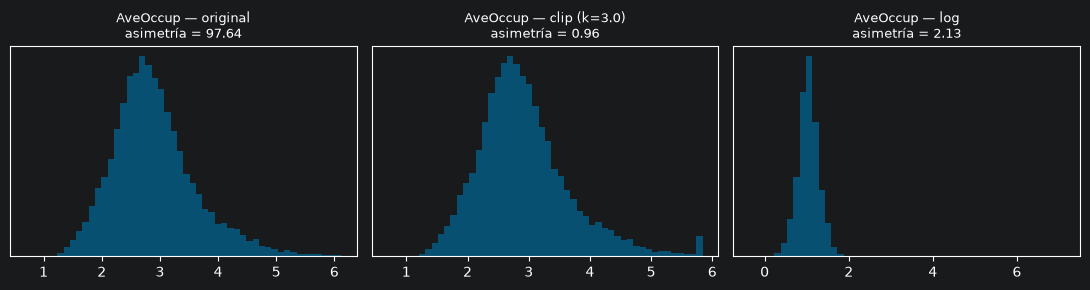

In [58]:
t, var = efecto("AveOccup")
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (nombre, v) in zip(axes, var.items()):
    tope = v.quantile(0.995) if nombre == "original" else v.max()
    ax.hist(v[v <= tope], bins=50, color=AZUL, alpha=0.85)
    ax.set_title(f"AveOccup — {nombre}\nasimetría = {v.skew():.2f}", fontsize=9)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

✏️ **Pregunta 7.1.** Mira `AveOccup`: ¿qué le pasa a la correlación de Pearson con `MedHouseVal` al recortar? ¿Y a la de Spearman?
¿Qué te dice eso sobre lo que hacían los valores extremos con $r$? (Pista: el logaritmo y el recorte casi no cambian el *orden* de los datos; ¿por qué Spearman casi no se mueve?)

✏️ **Pregunta 7.2.** Para `Population` el logaritmo deja la asimetría **negativa**. ¿Qué significa que se haya «pasado»? ¿Es un problema?

✏️ **Pregunta 7.3.** Cambia `k` en `efecto(c, k=3.0)` por `1.5` y compara. ¿Cuánta información pierdes al recortar con un $k$ más agresivo?

**Respuesta:**

<strong>7.1.</strong> La correlación de Pearson con `MedHouseVal` tiende a cambiar de 0 a -0.27 al recortar, mientras la de Spearman se mantiene en -0.257 en las tres versiones. En la de Pearson, se utilizan los valores. Esos pocos distritos con 1,243 o 600 personas por hogar estaban tan lejos que "jalaban" el cálculo y escondían la relación real. Al recortarlos, aparece la relación que Spearman ya veía. Spearman no cambia porque el recorte y el logaritmo no cambian el orden de los datos: el más grande sigue siendo el más grande. Si el orden es el mismo, Spearman da lo mismo.

<strong>7.2.</strong> El logaritmo comprime mucho los valores grandes y estira los pequeños. En `Population`, la cola larga de la derecha (distritos muy poblados) se encogió, mientras que los pocos distritos con poquísimos habitantes quedaron estirados hacia la izquierda. Por eso la asimetría pasó de +4.94 a -1.04: el logaritmo corrigió de más y la cola ahora está del otro lado. No es un problema grave, porque en valor absoluto la asimetría es mucho menor que la original y la curtosis bajó de 73.6 a 4.5, así que la distribución quedó más cercana a simétrica y casi sin valores extremos.

<strong>7.3.</strong> Con `k=1.5` se recortan muchas más filas que con `k=3`: en `AveOccup` pasan de 132 (0.64%) a 711 (3.44%), en `AveRooms` de 180 a 511 y en `Population` de 421 a 1,196 (5.79%). Todos esos valores se reemplazan por el valor de la cerca, así que se pierde la diferencia entre valores moderadamente altos y valores absurdos; en la práctica, el recorte crea un tope artificial. A cambio, la asimetría y la curtosis bajan un poco más, pero la correlación con `MedHouseVal` casi no cambia (en `AveOccup`, de -0.271 a -0.281). Un `k` más agresivo pierde mucha información para una mejora mínima, por lo que `k=3` parece un mejor equilibrio.

### Aplicar sus decisiones

Completa el diccionario con la acción que elijas para cada variable: `"ninguno"`, `"clip"` o `"log"`.
La función `aplicar` crea una copia transformada; luego comparamos la asimetría antes y después.

> ⚠️ **Fugas.** Aquí calculamos las cercas con *todos* los datos para simplificar. En un proyecto real, las cercas (y medias, etc.) se
> calculan **solo con el conjunto de entrenamiento** y se reutilizan en validación y prueba (como vimos en la sesión 1).

In [61]:
decisiones = {  # ✏️ cambia las decisiones y vuelve a ejecutar esta celda y las siguientes
    "MedInc": "ninguno",
    "HouseAge": "ninguno",
    "AveRooms": "clip",
    "AveBedrms": "clip",
    "Population": "log",
    "AveOccup": "clip",
    "Latitude": "ninguno",
    "Longitude": "ninguno",
}


def aplicar(d, decisiones, k=3.0):
    out = d.copy()
    for c, accion in decisiones.items():
        if accion == "clip":
            out[c] = out[c].clip(*cercas_iqr(out[c], k))
        elif accion == "log":
            out[c] = logaritmo(out[c])
        elif accion != "ninguno":
            raise ValueError(f"acción desconocida para {c}: {accion!r}")
    return out


df_t = aplicar(df, decisiones)
comp = pd.DataFrame({"asimetria_antes": df.skew(), "asimetria_despues": df_t.skew(),
                     "curtosis_antes": df.kurt(), "curtosis_despues": df_t.kurt()})
comp.round(2)

,asimetria_antes,asimetria_despues,curtosis_antes,curtosis_despues
MedInc,1.65,1.65,4.95,4.95
HouseAge,0.06,0.06,-0.80,-0.80
AveRooms,20.70,0.89,879.35,2.23
AveBedrms,31.32,1.17,1636.71,2.61
Population,4.94,-1.04,73.55,4.48
AveOccup,97.64,0.96,10651.01,1.65
Latitude,0.47,0.47,-1.12,-1.12
Longitude,-0.30,-0.30,-1.33,-1.33
MedHouseVal,0.98,0.98,0.33,0.33


---
## Parte 8 — Análisis bivariado

Con $n=20\,640$ puntos, una dispersión simple se **satura** (puntos encimados). Comparamos con un *hexbin*, que cuenta puntos por celda,
y miramos `MedHouseVal` por grupos de ingreso.

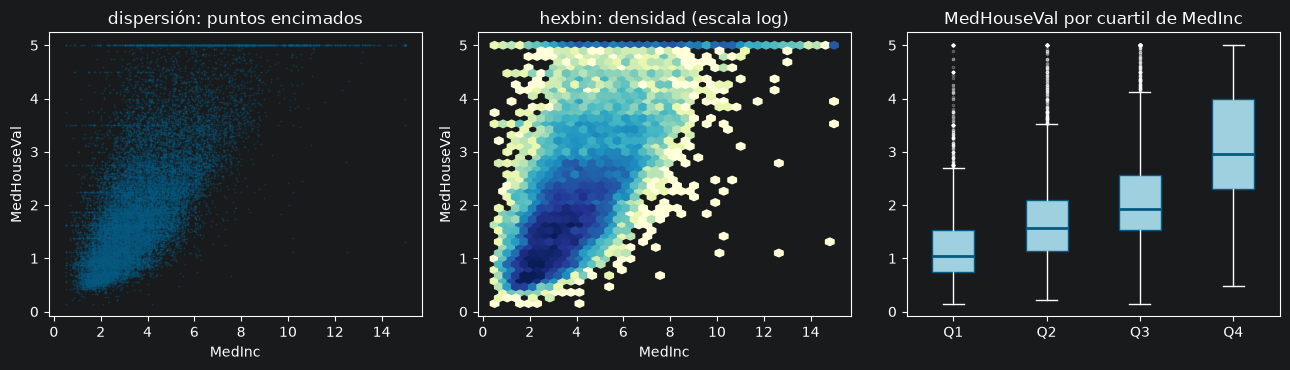

r de Pearson = 0.688    rho de Spearman = 0.677


In [69]:
X_NOMBRE = "MedInc"  # ✏️ cambia la variable y vuelve a ejecutar (prueba AveOccup, HouseAge, Latitude…)
Y_NOMBRE = "MedHouseVal"

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].scatter(df[X_NOMBRE], df[Y_NOMBRE], s=2, color=AZUL, alpha=0.4, lw=0)
axes[0].set_title("dispersión: puntos encimados")
hb = axes[1].hexbin(df[X_NOMBRE], df[Y_NOMBRE], gridsize=40, cmap="YlGnBu", mincnt=1, bins="log")
axes[1].set_title("hexbin: densidad (escala log)")
grupos = pd.qcut(df[X_NOMBRE], 4, labels=["Q1", "Q2", "Q3", "Q4"])
axes[2].boxplot([df.loc[grupos == g, Y_NOMBRE] for g in grupos.cat.categories], patch_artist=True,
                boxprops=dict(facecolor="#9FD0E0", edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
                flierprops=dict(markersize=1.5, alpha=0.3))
axes[2].set_xticklabels(grupos.cat.categories)
axes[2].set_title(f"{Y_NOMBRE} por cuartil de {X_NOMBRE}")
for ax in axes[:2]:
    ax.set_xlabel(X_NOMBRE);
    ax.set_ylabel(Y_NOMBRE)
plt.tight_layout()
plt.show()
print(
    f"r de Pearson = {df[X_NOMBRE].corr(df[Y_NOMBRE]):.3f}    rho de Spearman = {df[X_NOMBRE].corr(df[Y_NOMBRE], method='spearman'):.3f}")

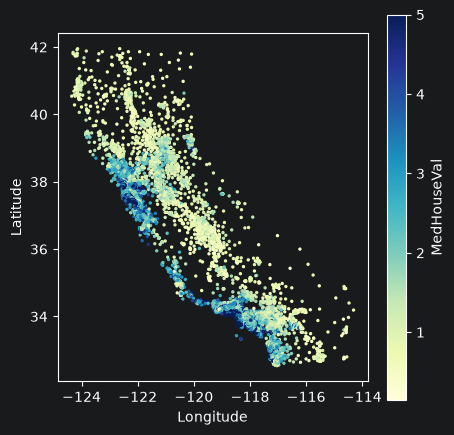

In [67]:
# Mapa: la ubicación también cuenta
plt.figure(figsize=(5, 5))
sc = plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"], s=2, cmap="YlGnBu")
plt.colorbar(sc, label="MedHouseVal")
plt.xlabel("Longitude");
plt.ylabel("Latitude")
plt.gca().set_aspect(1.2)
plt.grid(False)
plt.show()

✏️ **Pregunta 8.1.** En la primera gráfica (`MedInc` vs `MedHouseVal`), ¿qué es la línea horizontal de puntos arriba? ¿Cómo la relacionas con la Parte 6?
¿Qué ventaja da el hexbin sobre la dispersión?

✏️ **Pregunta 8.2.** ¿Cómo cambia la mediana de `MedHouseVal` al pasar de Q1 a Q4 de ingreso? ¿Es monótona?

✏️ **Pregunta 8.3.** En el mapa, ¿dónde están los distritos más caros? ¿Qué otro factor (distinto de `MedInc`)
podría estar influyendo tanto en el ingreso como en el precio? (recuerda *correlación ≠ causalidad*)

**Respuesta:**

<strong>8.1.</strong> La línea horizontal de arriba son los 992 distritos con tope de la Parte 6: su precio real era mayor o igual a 5.0, pero se registró como 5.0, así que son valores censurados que quedan aplastados contra un techo. Aparece sobre todo en ingresos altos, que es donde están las casas más caras. El hexbin resuelve la saturación de la dispersión: cuenta cuántos puntos caen en cada celda y lo muestra con el color, así que se ve dónde se concentran los datos. Por ejemplo, la mayoría de los distritos están en ingresos y precios bajos o medios, aunque en la dispersión todo parezca una mancha uniforme.

<strong>8.2.</strong> La mediana de MedHouseVal casi se triplica de Q1 a Q4: 1.04 → 1.56 → 1.93 → 2.95. El salto más grande está entre Q3 y Q4. Sí es monótona: sube en cada paso y nunca baja. Además, en Q4 el 15% de los distritos está en el tope de 5.0, así que su mediana probablemente está subestimada y el aumento real podría ser mayor.

<strong>8.3.</strong> En el mapa, los distritos más caros (puntos más oscuros) se concentran en la costa, sobre todo en el Área de la Bahía de San Francisco, Los Ángeles y San Diego; el interior del estado es más barato. Otro factor que podría influir tanto en el ingreso como en el precio es la ubicación, en particular la cercanía a la costa y a las grandes ciudades. Ahí hay más empleos bien pagados, lo que eleva el ingreso, y más demanda de vivienda con poco terreno disponible, lo que eleva el precio. La ubicación actúa como una variable de confusión: ingreso y precio están correlacionados, en parte porque ambos dependen de dónde está el distrito, así que la correlación no prueba que el ingreso cause el precio.

---
## Parte 9 — Matriz de correlación, heatmap y multicolinealidad

Con 9 variables hay $\binom92=36$ pares. La matriz $R=\frac1{n-1}Z^\top Z$ (con $Z$ las columnas estandarizadas) los resume.
Seguimos las buenas prácticas de la presentación: escala **divergente centrada en 0**, solo el **triángulo inferior** y **valores anotados**.

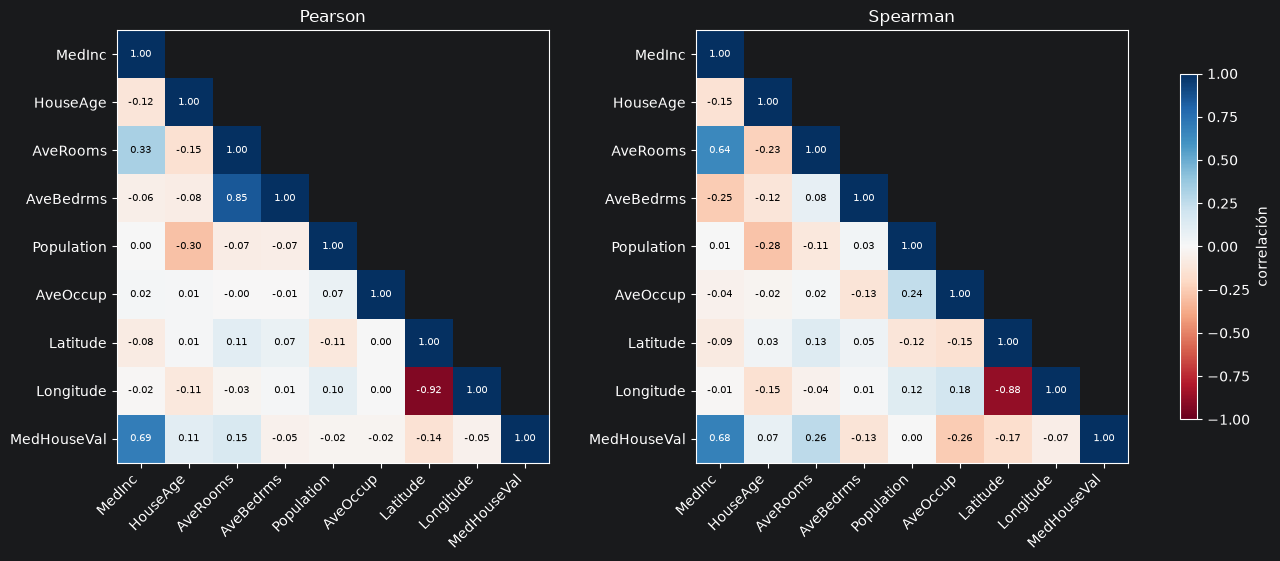

In [70]:
def heatmap(Cm, ax, titulo):
    mask = np.triu(np.ones(Cm.shape, dtype=bool), k=1)  # oculta el triángulo superior (es repetido)
    im = ax.imshow(np.ma.array(Cm.values, mask=mask), cmap="RdBu", vmin=-1, vmax=1)
    n = len(Cm)
    ax.set_xticks(range(n));
    ax.set_xticklabels(Cm.columns, rotation=45, ha="right")
    ax.set_yticks(range(n));
    ax.set_yticklabels(Cm.index)
    ax.grid(False)
    for i in range(n):
        for j in range(i + 1):
            v = Cm.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
    ax.set_title(titulo)
    return im


Cp = df.corr()  # Pearson
Cs = df.corr(method="spearman")  # Spearman = Pearson de los rangos
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
heatmap(Cp, axes[0], "Pearson")
im = heatmap(Cs, axes[1], "Spearman")
fig.colorbar(im, ax=axes, shrink=0.8, label="correlación")
plt.show()

In [71]:
# Los pares más fuertes (sin repetir y sin la diagonal)
tri = np.tril(np.ones(Cp.shape, dtype=bool), k=-1)
pares = Cp.where(tri).stack().rename("pearson").to_frame()
pares["spearman"] = Cs.where(tri).stack()
pares["|pearson|"] = pares["pearson"].abs()
pares.sort_values("|pearson|", ascending=False).head(6).round(2)

,,pearson,spearman,|pearson|
Longitude,Latitude,-0.92,-0.88,0.92
AveBedrms,AveRooms,0.85,0.08,0.85
MedHouseVal,MedInc,0.69,0.68,0.69
AveRooms,MedInc,0.33,0.64,0.33
Population,HouseAge,-0.30,-0.28,0.30
AveRooms,HouseAge,-0.15,-0.23,0.15


In [72]:
# Pearson vs Spearman con el objetivo: ¿en qué variables difieren más?
vs = pd.DataFrame({"pearson": Cp["MedHouseVal"], "spearman": Cs["MedHouseVal"]}).drop("MedHouseVal")
vs["diferencia"] = (vs["spearman"] - vs["pearson"]).abs()
vs.sort_values("diferencia", ascending=False).round(2)

,pearson,spearman,diferencia
AveOccup,-0.02,-0.26,0.23
AveRooms,0.15,0.26,0.11
AveBedrms,-0.05,-0.13,0.08
HouseAge,0.11,0.07,0.03
Population,-0.02,0.00,0.03
Longitude,-0.05,-0.07,0.02
Latitude,-0.14,-0.17,0.02
MedInc,0.69,0.68,0.01


✏️ **Pregunta 9.1.** ¿Qué variable se correlaciona más con el objetivo? ¿Cuál es el par de variables **predictoras** más correlacionado (Pearson)? ¿Y el segundo?
¿Tienen sentido en el contexto (geografía, tamaño de las viviendas)?

✏️ **Pregunta 9.2.** ¿En qué variable difieren más Pearson y Spearman con el objetivo? Mira también el par `AveBedrms`–`AveRooms`: ¿qué le pasa a su correlación al pasar de Pearson a Spearman?
Conecta con lo que viste en las Partes 4, 5 y 7: ¿qué estaban haciendo los atípicos con $r$? ¿Qué implica para decir que dos variables son «redundantes»?

**Respuesta:**

<strong>9.1.</strong> La variable más correlacionada con el objetivo es MedInc ($r$ = 0.69). El par de predictoras más correlacionado es Longitude–Latitude ($r$ = −0.92), lo que tiene sentido por la forma diagonal de California: al ir hacia el norte también se avanza hacia el oeste. El segundo par es AveBedrms–AveRooms ($r$ = 0.85), también lógico, porque las recámaras forman parte de las habitaciones y las viviendas con más habitaciones suelen tener más recámaras.

<strong>9.2.</strong> Pearson y Spearman difieren más con el objetivo en AveOccup (−0.02 vs. −0.26): sus valores extremos esconden a Pearson la relación negativa que Spearman sí detecta, como vimos en la Parte 7. En el par AveBedrms–AveRooms, la correlación cae de 0.85 con Pearson a 0.08 con Spearman. Esto ocurre porque los pocos distritos extremos de la Parte 5 (zonas vacacionales con muy pocos hogares) tienen a la vez valores enormes en ambas variables y fabrican una correlación alta en Pearson. Al quitar solo los 69 distritos con AveRooms > 20, Pearson baja de 0.85 a 0.49. Por eso, un Pearson alto no basta para decir que dos variables son redundantes: hay que comprobar que la relación no la creen unos pocos atípicos.

### Multicolinealidad

Con predictores muy correlacionados, los coeficientes de una regresión lineal se vuelven inestables. El **factor de inflación de la varianza**
mide qué tan bien se explica cada predictor con los demás:

$$\mathrm{VIF}_j=\frac{1}{1-R_j^2}\;=\;\big[R^{-1}\big]_{jj}\quad(\text{el }j\text{-ésimo elemento de la diagonal de la inversa de la matriz de correlación}).$$

Regla práctica: $\mathrm{VIF}>5$–$10$ es una alerta.

In [73]:
def vif(X):
    R = X.corr().values
    return pd.Series(np.diag(np.linalg.inv(R)), index=X.columns, name="VIF")


X = df.drop(columns="MedHouseVal")
vif(X).round(1)

MedInc        2.5
HouseAge      1.2
AveRooms      8.3
AveBedrms     7.0
Population    1.1
AveOccup      1.0
Latitude      9.3
Longitude     9.0
Name: VIF, dtype: float64

✏️ **Pregunta 9.3.** ¿Qué variables tienen VIF alto? ¿Las habías anticipado con el heatmap? ¿Esa colinealidad es «real» para todo el conjunto o la crean unos pocos distritos extremos? (revisa los Spearman de la Parte 9)

✏️ **Pregunta 9.4.** Quita **una** de las variables con VIF alto (la que consideres más redundante, p. ej. `AveBedrms`) en la celda de abajo y vuelve a calcular.
¿Cuánto baja el VIF de su «pareja»? ¿Qué variable elegirías conservar y por qué?

**Respuesta:**

<strong>9.3.</strong> Tienen VIF alto Latitude (9.3), Longitude (9.0), AveRooms (8.3) y AveBedrms (7.0), lo que se podía anticipar con el heatmap, porque son los dos pares más correlacionados. Sin embargo, no es el mismo tipo de colinealidad. La de AveRooms–AveBedrms la crean unos pocos distritos extremos: al quitar los 69 con AveRooms > 20, sus VIF bajan a 3.5 y 2.0, y con Spearman a 2.5 y 1.3. En cambio, la de Latitude–Longitude es real para todo el conjunto: sin esos distritos sus VIF siguen en 9.8 y 9.4, y con Spearman cerca de 6, porque se debe a la forma diagonal de California.

In [74]:
# ✏️ Pregunta 9.4: elige qué variable quitar y compara
a_quitar = ["AveBedrms"]
vif(X.drop(columns=a_quitar)).round(1)

MedInc        1.3
HouseAge      1.2
AveRooms      1.3
Population    1.1
AveOccup      1.0
Latitude      8.8
Longitude     8.7
Name: VIF, dtype: float64

<strong>9.4.</strong> Al quitar AveBedrms, el VIF de su pareja AveRooms baja de 8.3 a 1.3, y el de MedInc de 2.5 a 1.3, mientras que Latitude y Longitude casi no cambian (8.8 y 8.7), porque su colinealidad es entre ellas. Conservaría AveRooms: tiene más relación con el objetivo (Spearman 0.26 contra −0.13 de AveBedrms) y es más general, porque las habitaciones ya incluyen las recámaras.

---
## Parte 10 — Resumen y entregable

Rellena la tabla con **una fila por variable predictora**. La columna `pct_atipicos` ya está calculada con la regla del IQR ($k=1.5$);
las columnas `decision` y `justificacion` las completas tú.

| variable | % atípicos | decisión | justificación |
|---|---|---|---|
| *(ejemplo)* `AveOccup` | 3.4 | `clip` en $3\cdot$IQR | casi todos los distritos tienen ≈3 ocupantes; los valores > 50 corresponden a distritos con muy pocos hogares (residencias colectivas) y arrastran la media y a $r$ |

Una buena justificación responde: **¿por qué es (o no) un error?**, **¿qué pasaría con el análisis si lo dejamos?** y **¿cómo documento la decisión?**

In [78]:
entrega = tabla_atipicos(df.drop(columns="MedHouseVal"), 1.5)[["pct_atipicos"]].round(1).copy()

filas = {
    "MedInc": (
        "ninguno",
        "No es un error: son ingresos altos reales (cola derecha moderada, asimetría ≈ 1.6). Pearson y Spearman con el "
        "objetivo casi coinciden (0.69 / 0.68), así que los extremos no distorsionan r; recortarlos quitaría señal de la "
        "variable más predictiva. El tope en 15.0 solo afecta 51 filas (0.25 %) y queda documentado.",
    ),
    "HouseAge": (
        "indicador",
        "0 % por IQR, pero 1 273 distritos (6.2 %) están censurados en 52 («52 años o más»). No es un error y transformar "
        "no recupera el valor real. Se conserva la variable y se agrega es_tope_edad = (HouseAge >= 52), porque ese grupo "
        "tiene una mediana de precio de 2.59 frente a ≈ 1.8 del resto.",
    ),
    "AveRooms": (
        "clip en 3·IQR",
        "No es error de captura: son zonas vacacionales con muy pocos hogares (hasta ≈ 142 habitaciones por hogar). Si se "
        "dejan, fabrican la colinealidad con AveBedrms (Pearson 0.85 vs Spearman 0.08; VIF 8.3 → 3.5 sin 69 distritos). "
        "El clip con k = 3 modifica 180 filas (0.9 %); log sería una alternativa casi equivalente (asimetría 0.87).",
    ),
    "AveBedrms": (
        "clip en 3·IQR",
        "El 6.9 % se debe a cercas muy angostas (0.87–1.24): la mayoría son valores razonables (≈ 1.3 recámaras). Los "
        "absurdos (hasta 34) son los mismos distritos vacacionales que AveRooms. Clip con k = 3 (724 filas, 3.5 %). En un "
        "modelo lineal es la candidata a eliminar por redundante: sin ella, el VIF de AveRooms baja de 8.3 a 1.3.",
    ),
    "Population": (
        "log",
        "Conteo con cola larga real (asimetría 4.9, curtosis 73.6); no son errores. log(1 + x) conserva el orden y la "
        "información: la asimetría baja a −1.0 y la curtosis a 4.5. La cola izquierda que aparece son distritos con "
        "poquísimos habitantes, ya cubiertos por la regla de exclusión de la Parte 5.",
    ),
    "AveOccup": (
        "clip en 3·IQR + marcar",
        "No son errores sino alojamientos colectivos (cárceles, residencias, cuarteles): p. ej. 7 460 personas en ≈ 6 "
        "hogares. Si se dejan, aplastan a Pearson con el objetivo (−0.02 vs Spearman −0.26); el clip con k = 3 (132 filas, "
        "0.6 %) recupera r = −0.27. Además se marcan con la regla de la Parte 5 (< 10 hogares, AveRooms > 20 o "
        "AveOccup > 15: 134 distritos) para poder excluirlos.",
    ),
    "Latitude": (
        "ninguno",
        "Acotada por la geografía de California: 0 % de atípicos. Tiene colinealidad real con Longitude (r = −0.92, "
        "VIF 9.3, se mantiene con Spearman), pero se conservan ambas: juntas ubican el distrito, y la ubicación es clave "
        "para el precio.",
    ),
    "Longitude": (
        "ninguno",
        "Igual que Latitude: acotada por la geografía y sin atípicos. Su VIF alto (9.0) refleja la forma diagonal del "
        "estado; quitar una de las dos coordenadas perdería la ubicación.",
    ),
}
entrega["decision"] = pd.Series({v: d for v, (d, _) in filas.items()})
entrega["justificacion"] = pd.Series({v: j for v, (_, j) in filas.items()})
pd.set_option("display.max_colwidth", 80)
entrega

,pct_atipicos,decision,justificacion
variable,,,
MedInc,3.3,ninguno,"No es un error: son ingresos altos reales (cola derecha moderada, asimetría ..."
HouseAge,0.0,indicador,"0 % por IQR, pero 1 273 distritos (6.2 %) están censurados en 52 («52 años o..."
AveRooms,2.5,clip en 3·IQR,No es error de captura: son zonas vacacionales con muy pocos hogares (hasta ...
AveBedrms,6.9,clip en 3·IQR,El 6.9 % se debe a cercas muy angostas (0.87–1.24): la mayoría son valores r...
Population,5.8,log,"Conteo con cola larga real (asimetría 4.9, curtosis 73.6); no son errores. l..."
AveOccup,3.4,clip en 3·IQR + marcar,"No son errores sino alojamientos colectivos (cárceles, residencias, cuartele..."
Latitude,0.0,ninguno,Acotada por la geografía de California: 0 % de atípicos. Tiene colinealidad ...
Longitude,0.0,ninguno,Igual que Latitude: acotada por la geografía y sin atípicos. Su VIF alto (9....


In [79]:
# Cuando termines, guarda la tabla y súbela junto con este notebook
# (edita primero las columnas «decision» y «justificacion» en la celda anterior, p. ej. con entrega.loc["AveOccup", "decision"] = "clip")
entrega.to_csv("entregable_unidad1.csv", encoding="utf-8")
print("Guardado: entregable_unidad1.csv")

Guardado: entregable_unidad1.csv


### Reflexión final (3–5 líneas)

1. ¿Qué hallazgo del EDA **cambiaría** la forma en que entrenarías un modelo para predecir `MedHouseVal`?
2. ¿Qué decisión de la tabla es la más **discutible** y qué evidencia adicional pedirías?
3. Dos *trampas* de la presentación que aparecieron en este conjunto de datos (por ejemplo: topes, correlaciones aplastadas por atípicos, multicolinealidad…).

**Respuesta:**


<strong>Reflexión final.</strong>

1. El hallazgo que más cambiaría el entrenamiento es el **tope de 5.0 en el objetivo**: 992 distritos (4.8 %), concentrados en ingresos altos (15 % del cuartil Q4). No los borraría, porque introduciría un sesgo de selección; los conservaría con un indicador `es_tope` y reportaría el desempeño también en la zona no truncada (`MedHouseVal < 5.0`), sabiendo que el modelo no podrá predecir valores mayores a 5.0. También incluiría la ubicación, porque el mapa muestra que influye tanto en el ingreso como en el precio.
2. La decisión más discutible es la de `AveRooms` (clip vs. log) y, en general, excluir los 134 distritos marcados en la Parte 5. Pediría evidencia del censo sobre esos distritos (tasa de viviendas desocupadas, población en alojamientos colectivos) y compararía con validación cruzada el desempeño del modelo con cada opción.
3. Trampas que aparecieron: **topes** (5.0 y 52 dan 0 % de atípicos con IQR aunque están censurados) y **correlaciones distorsionadas por atípicos** (`AveOccup`: Pearson −0.02 vs Spearman −0.26; `AveRooms`–`AveBedrms`: 0.85 vs 0.08). También hay **multicolinealidad**, que es real en `Latitude`–`Longitude` y fabricada por extremos en `AveRooms`–`AveBedrms`.

---
### Reto opcional

Compara la regla del IQR con la regla del puntaje $z$ ($|z|>3$) en `AveOccup` y en `MedInc`: ¿cuántos puntos marca cada una?
¿Cuál es más sensible a los propios atípicos, y por qué? (Pista: el $z$ usa $\bar x$ y $s$, que los atípicos *contaminan*; el IQR usa cuartiles.)

In [80]:
# Reto opcional: IQR vs |z| > 3
for c in ["AveOccup", "MedInc"]:
    x = df[c]
    lo, hi = cercas_iqr(x, 1.5)
    n_iqr = int(((x < lo) | (x > hi)).sum())
    n_z = int((((x - x.mean()) / x.std()).abs() > 3).sum())
    print(f"{c:9s}: IQR(1.5) marca {n_iqr:5d}   |z|>3 marca {n_z:5d}")

AveOccup : IQR(1.5) marca   711   |z|>3 marca     8
MedInc   : IQR(1.5) marca   681   |z|>3 marca   345


<strong>Reto opcional.</strong> En `AveOccup`, la regla del IQR marca 711 puntos y $|z|>3$ solo 8; en `MedInc`, 681 contra 345. La regla del puntaje $z$ es mucho más sensible a los propios atípicos: usa $\bar x$ y $s$, y los valores extremos los inflan. En `AveOccup`, los pocos distritos con cientos de ocupantes por hogar elevan $s$ a ≈ 10.4, así que la cerca queda en ≈ 3.07 + 3·10.4 ≈ 34 y casi nada la supera (efecto de *enmascaramiento*). La regla del IQR usa cuartiles, que casi no se mueven con unos pocos extremos, por lo que es más robusta. En `MedInc` la diferencia es menor porque su cola es moderada y no contamina tanto a $s$.